In [1]:
import numpy as np
import pandas as pd
import struct
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

In [2]:
train = pd.read_csv("mnist_train.csv")
test = pd.read_csv("mnist_test.csv")

X_train = train.drop("label", axis=1).values
y_train = train["label"].values

X_test = test.drop("label", axis=1).values
y_test = test["label"].values

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (60000, 784)
Testing: (10000, 784)


In [3]:
X_train = X_train.reshape(-1,28,28)/255.0
X_test = X_test.reshape(-1,28,28)/255.0

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (60000, 28, 28)
Testing: (10000, 28, 28)


In [4]:
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28,28)),

    keras.layers.Dense(128,activation="relu"),
    keras.layers.Dense(64,activation="relu"),
    keras.layers.Dense(10,activation="softmax")
])

C:\Users\Avadhut\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [5]:
model.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01),
    loss = "sparse_categorical_crossentropy",
    metrics=["accuracy"]
    
)


In [6]:
history = model.fit(
    X_train,y_train,
    epochs=11,
    validation_data=(X_test,y_test)
)

Epoch 1/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8330 - loss: 0.6233 - val_accuracy: 0.9090 - val_loss: 0.3163
Epoch 2/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9174 - loss: 0.2884 - val_accuracy: 0.9288 - val_loss: 0.2452
Epoch 3/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9321 - loss: 0.2363 - val_accuracy: 0.9387 - val_loss: 0.2129
Epoch 4/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9413 - loss: 0.2027 - val_accuracy: 0.9434 - val_loss: 0.1857
Epoch 5/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9486 - loss: 0.1779 - val_accuracy: 0.9499 - val_loss: 0.1665
Epoch 6/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9543 - loss: 0.1584 - val_accuracy: 0.9539 - val_loss: 0.1497
Epoch 7/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9596 - loss: 0.1423 - val_accuracy: 0.9565 - val_loss: 0.1402
Epoch 8/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9628 - loss: 0.1291 - 

In [7]:
loss, accuracy = model.evaluate(X_test,y_test)

print("Loss", loss)
print("accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9672 - loss: 0.1097 
Loss 0.1097436398267746
accuracy: 0.967199981212616


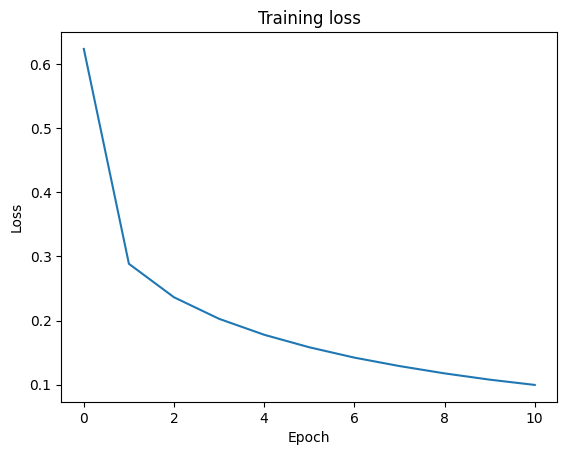

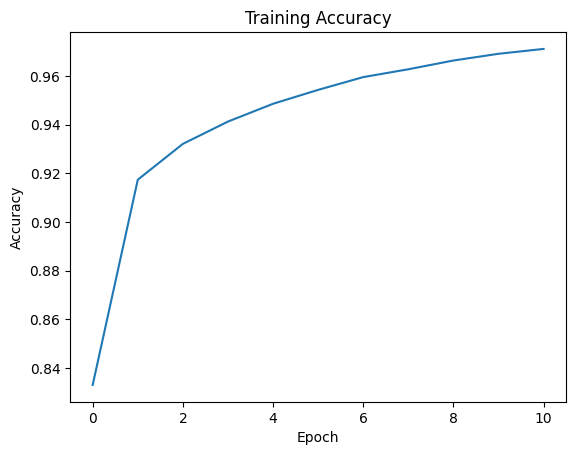

In [8]:
plt.plot(history.history["loss"])
plt.title("Training loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

plt.plot(history.history["accuracy"])
plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


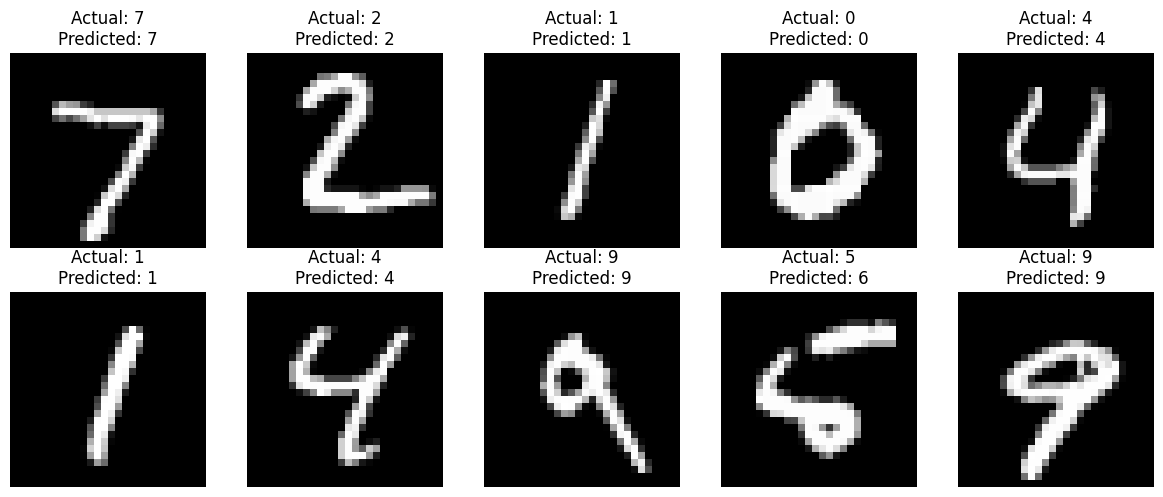

In [9]:
predictions = model.predict(X_test)

plt.figure(figsize=(12,5))

for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(X_test[i], cmap="gray")
    actual = y_test[i]
    predicted = np.argmax(predictions[i])
    plt.title(f"Actual: {actual}\nPredicted: {predicted}")
    plt.axis("off")

plt.tight_layout()
plt.show()
    